<a href="https://colab.research.google.com/github/Manjot0005/data266-6359/blob/hw7/HW7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Generative Models: GANs (Theory) and AutoEncoders on FashionMNIST (PyTorch)

**Part 1** answers the GAN theory questions. **Part 2** trains and evaluates a Fully Connected AutoEncoder (FC-AE) and a Variational AutoEncoder (VAE) on FashionMNIST.

# Part 1: Generative Adversarial Networks

## 1.1 How a GAN works

A GAN (Goodfellow et al., 2014) is made of two networks that compete with each other.

The **generator** $G$ takes a random noise vector $z$, usually drawn from a standard Gaussian, and turns it into a fake sample such as an image. It never looks at real data. It learns only from the feedback it gets through the discriminator.

The **discriminator** $D$ is a classifier. Given an input $x$, it outputs a probability $D(x)$ that $x$ is real rather than produced by the generator.

Training is a game between the two. The discriminator tries to tell real from fake, and the generator tries to fool it. This is written as a minimax objective:

$$
\min_G \max_D \; V(D,G) = \mathbb{E}_{x\sim p_{\text{data}}}[\log D(x)] + \mathbb{E}_{z\sim p_z}[\log(1 - D(G(z)))]
$$

In practice the two networks take turns. First we update $D$ on a batch of real images (label 1) and a batch of generated images (label 0), using ordinary binary cross-entropy. Then we update $G$: we generate new fakes, pass them through $D$, and backpropagate through $D$ into $G$ so that its outputs get scored as "more real." $D$ acts as a learned loss function that keeps getting harder to fool.

One practical detail: early on, $D$ rejects fakes easily, and the term $\log(1 - D(G(z)))$ gives almost no gradient. So the generator is usually trained to maximise $\log D(G(z))$ instead. This has the same goal but gives much stronger gradients at the start.

**The theoretical goal.** For a fixed generator, the best possible discriminator is

$$
D^*(x) = \frac{p_{\text{data}}(x)}{p_{\text{data}}(x) + p_g(x)}
$$

Plugging this back into the objective shows that the generator is minimising the Jensen–Shannon divergence between the real distribution $p_{\text{data}}$ and its own distribution $p_g$. That divergence is zero only when the two are identical. So the ideal end point is $p_g = p_{\text{data}}$: the generator produces samples indistinguishable from real data, and the discriminator can only guess, outputting $1/2$ everywhere. This is the Nash equilibrium of the game. In practice we rarely reach it cleanly, because the networks have finite capacity and $D$ is never trained to optimality at each step.

## 1.2 Mode collapse

Mode collapse is when the generator produces only a small part of the variety in the real data. Many different noise vectors end up mapping to the same or very similar outputs. The images may look realistic, but they lack diversity. For example, a GAN trained on FashionMNIST might generate convincing sneakers and almost nothing else.

**Why it happens.** The generator is always trained against the *current* discriminator, not the ideal one. Against a fixed discriminator, the easiest way to lower the loss is to put everything on whatever output $D$ currently finds most convincing. Nothing in the loss rewards variety. The discriminator then learns that this output is fake, so the generator jumps to a different one, and the two can keep chasing each other between modes instead of settling on a distribution that covers all of them. It also does not help that $D$ judges each sample on its own: a batch of identical but realistic images is not penalised. On top of that, when real and generated distributions barely overlap early in training, the JS divergence gives little useful gradient, so the generator follows whatever narrow signal it can find.

**Fix 1: Wasserstein GAN (WGAN / WGAN-GP).** WGAN (Arjovsky et al., 2017) replaces the JS divergence with the Wasserstein (Earth Mover's) distance, which roughly measures how much "work" it takes to move one distribution onto the other. The discriminator becomes a *critic* that outputs a real-valued score instead of a probability, and it must be 1-Lipschitz. WGAN-GP (Gulrajani et al., 2017) enforces this with a gradient penalty that keeps the critic's gradient norm close to 1 on points between real and fake samples.

This helps because the Wasserstein distance still gives meaningful gradients when the two distributions do not overlap. And since the critic cannot saturate, it can be trained close to optimal without killing the generator's gradients. A well-trained critic points the generator toward *all* regions of the real data, not just the one it is currently exploiting. A side benefit is that the critic's loss actually tracks sample quality, which makes training easier to monitor.

**Fix 2: Minibatch discrimination.** Salimans et al. (2016) let the discriminator look at a whole batch instead of single samples. For each sample, it computes how similar that sample is to the others in the batch and uses this as an extra feature. ProGAN and StyleGAN use a simpler version: they compute the standard deviation of the features across the batch and append it as an extra channel.

This works because real batches are naturally diverse. If the generator collapses, its batches look suspiciously uniform and the discriminator can catch that. The resulting gradient pushes the generator's samples apart, which directly penalises the lack of diversity.

## 1.3 Three GAN variants

**DCGAN (Radford et al., 2016).** Early GANs mostly used fully connected layers, and attempts to use CNNs were unstable. DCGAN gave a set of architectural rules that made convolutional GANs train reliably. It replaces pooling with strided convolutions in the discriminator and transposed convolutions in the generator, adds batch normalisation to both networks, removes fully connected hidden layers, and uses ReLU in the generator (Tanh at the output) and LeakyReLU in the discriminator. It also recommended Adam with a learning rate of 0.0002 and $\beta_1 = 0.5$. DCGAN became the standard baseline, and it showed that the latent space is meaningful: interpolating between points gives smooth transitions, and simple vector arithmetic on latent codes changes attributes in predictable ways.

**StyleGAN (Karras et al., 2019).** Earlier high-resolution GANs could produce realistic faces but gave little control over what was generated, because attributes like pose, identity, and hair were tangled together in $z$. StyleGAN adds a mapping network that turns $z$ into an intermediate code $w$, which ends up more disentangled. The generator starts from a learned constant instead of $z$, and $w$ is injected at every layer through Adaptive Instance Normalisation (AdaIN). Early layers control coarse features like pose and face shape, and later layers control fine details like colour and texture. Random noise is added at each layer for small stochastic details such as hair strands or freckles. During training, two different codes are sometimes mixed across layers (style mixing), which keeps the layers' styles independent.

**CycleGAN (Zhu et al., 2017).** Image-to-image translation methods like pix2pix need paired examples, such as the same scene photographed in summer and winter, which are often impossible to collect. With unpaired data, a normal GAN could map an input to any realistic output and ignore its content. CycleGAN uses two generators, $G: X \to Y$ and $F: Y \to X$, each with its own discriminator, and adds a cycle-consistency loss: translating an image to the other domain and back should give the original image,

$$
\mathcal{L}_{\text{cyc}} = \mathbb{E}_x\|F(G(x)) - x\|_1 + \mathbb{E}_y\|G(F(y)) - y\|_1
$$

This forces the generators to keep the structure of the input and change only its appearance. It works well for things like horse ↔ zebra or photo ↔ painting, but struggles with large shape changes, such as turning a cat into a dog.

---
# Part 2 — AutoEncoders on FashionMNIST

Both models use the **same encoder/decoder backbone** (784 → 512 → 256 → latent 16 → 256 → 512 → 784) and are trained with the same optimiser, epochs, and reconstruction loss. The only difference is the VAE's probabilistic bottleneck and KL term, so the comparison is fair.

**Evaluation plan**
1. Training / validation loss curves
2. Test reconstruction error (MSE, BCE, PSNR), overall and per class
3. Visual reconstructions
4. Latent-space structure (t-SNE) and linear-probe classification accuracy on the latent codes
5. Generation from random latent samples
6. Latent interpolation between two test images

In [1]:
import time, random, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Hyperparameters (shared by both models)
LATENT_DIM = 16
BATCH_SIZE = 128
EPOCHS     = 20
LR         = 1e-3

CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

Device: cuda


## 2.1 Data
Pixels are scaled to [0, 1] (no mean/std normalisation) so a sigmoid output and binary cross-entropy reconstruction loss are appropriate. 5,000 training images are held out for validation.

100%|██████████| 26.4M/26.4M [00:00<00:00, 115MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 3.39MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 58.0MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 29.9MB/s]


train 55000, val 5000, test 10000


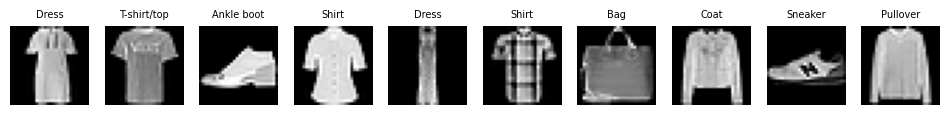

In [2]:
transform = transforms.ToTensor()   # -> [0, 1], shape (1, 28, 28)
full_train = datasets.FashionMNIST("./data", train=True,  download=True, transform=transform)
test_set   = datasets.FashionMNIST("./data", train=False, download=True, transform=transform)

train_set, val_set = random_split(full_train, [55_000, 5_000],
                                  generator=torch.Generator().manual_seed(SEED))

kw = dict(num_workers=2, pin_memory=(device.type == "cuda"))
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  **kw)
val_loader   = DataLoader(val_set,   batch_size=512, shuffle=False, **kw)
test_loader  = DataLoader(test_set,  batch_size=512, shuffle=False, **kw)

print(f"train {len(train_set)}, val {len(val_set)}, test {len(test_set)}")

# Peek at the data
x, y = next(iter(train_loader))
fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for i, ax in enumerate(axes):
    ax.imshow(x[i, 0], cmap="gray"); ax.set_title(CLASSES[y[i]], fontsize=7); ax.axis("off")
plt.show()

## 2.2 Models

In [3]:
class Encoder(nn.Module):
    # 784 -> 512 -> 256 (shared trunk)
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 512), nn.ReLU(),
            nn.Linear(512, 256), nn.ReLU(),
        )
    def forward(self, x): return self.net(x)

class Decoder(nn.Module):
    # latent -> 256 -> 512 -> 784, sigmoid output in [0, 1]
    def __init__(self, latent_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.ReLU(),
            nn.Linear(256, 512), nn.ReLU(),
            nn.Linear(512, 784), nn.Sigmoid(),
        )
    def forward(self, z): return self.net(z).view(-1, 1, 28, 28)


class FCAutoEncoder(nn.Module):
    # Deterministic bottleneck: z = f(x)
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = Encoder()
        self.to_z    = nn.Linear(256, latent_dim)
        self.decoder = Decoder(latent_dim)
    def encode(self, x): return self.to_z(self.encoder(x))
    def decode(self, z): return self.decoder(z)
    def forward(self, x):
        z = self.encode(x)
        return self.decode(z), z


class VAE(nn.Module):
    # Probabilistic bottleneck: q(z|x) = N(mu(x), diag(sigma^2(x)))
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder   = Encoder()
        self.fc_mu     = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        self.decoder   = Decoder(latent_dim)
    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)
    def reparameterize(self, mu, logvar):
        # z = mu + sigma * eps keeps sampling differentiable w.r.t. mu and sigma
        if self.training:
            std = torch.exp(0.5 * logvar)
            return mu + std * torch.randn_like(std)
        return mu   # use the posterior mean at evaluation time
    def decode(self, z): return self.decoder(z)
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
print("FC-AE params:", n_params(FCAutoEncoder()))
print("VAE   params:", n_params(VAE()))

FC-AE params: 1075488
VAE   params: 1079600


## 2.3 Losses

- **FC-AE:** reconstruction loss only, binary cross-entropy summed over the 784 pixels and averaged over the batch.
- **VAE:** negative ELBO = reconstruction BCE + KL divergence between $q(z|x)=\mathcal{N}(\mu,\sigma^2)$ and the prior $\mathcal{N}(0,I)$, in closed form:
$\;\mathrm{KL} = -\tfrac12\sum_j (1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2)$.

Using the same summed BCE for both keeps the reconstruction terms directly comparable.

In [4]:
def recon_bce(x_hat, x):
    # Sum over pixels, mean over batch
    return F.binary_cross_entropy(x_hat, x, reduction="sum") / x.size(0)

def kl_divergence(mu, logvar):
    return (-0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())) / mu.size(0)

def ae_loss(model, x):
    x_hat, _ = model(x)
    rec = recon_bce(x_hat, x)
    return rec, {"recon": rec.item()}

def vae_loss(model, x, beta=1.0):
    x_hat, mu, logvar = model(x)
    rec = recon_bce(x_hat, x)
    kl  = kl_divergence(mu, logvar)
    return rec + beta * kl, {"recon": rec.item(), "kl": kl.item()}

## 2.4 Training loop

In [5]:
def run_epoch(model, loader, loss_fn, optimizer=None):
    train = optimizer is not None
    model.train(train)
    totals, n = {}, 0
    with torch.set_grad_enabled(train):
        for x, _ in loader:
            x = x.to(device)
            loss, parts = loss_fn(model, x)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            b = x.size(0); n += b
            totals["loss"] = totals.get("loss", 0.0) + loss.item() * b
            for k, v in parts.items():
                totals[k] = totals.get(k, 0.0) + v * b
    return {k: v / n for k, v in totals.items()}

def train_model(model, loss_fn, name, epochs=EPOCHS, lr=LR):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    hist = {"train": [], "val": []}
    best_val, best_state = float("inf"), None
    t0 = time.time()
    for ep in range(1, epochs + 1):
        tr = run_epoch(model, train_loader, loss_fn, opt)
        va = run_epoch(model, val_loader, loss_fn)
        sched.step(va["loss"])
        hist["train"].append(tr); hist["val"].append(va)
        if va["loss"] < best_val:
            best_val = va["loss"]
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        extra = f" | val recon {va['recon']:.2f} KL {va['kl']:.2f}" if "kl" in va else ""
        print(f"[{name}] epoch {ep:2d}/{epochs}  train {tr['loss']:.2f}  val {va['loss']:.2f}{extra}  ({time.time()-t0:.0f}s)")
    model.load_state_dict(best_state)   # keep the best-on-validation weights
    torch.save(model.state_dict(), f"{name.lower().replace('-', '_')}.pt")
    return hist

In [6]:
fc_ae = FCAutoEncoder()
hist_ae = train_model(fc_ae, ae_loss, "FC-AE")

[FC-AE] epoch  1/20  train 266.46  val 238.05  (8s)
[FC-AE] epoch  2/20  train 232.79  val 229.90  (17s)
[FC-AE] epoch  3/20  train 226.73  val 225.55  (25s)
[FC-AE] epoch  4/20  train 223.26  val 222.62  (33s)
[FC-AE] epoch  5/20  train 220.84  val 220.62  (41s)
[FC-AE] epoch  6/20  train 219.07  val 218.97  (49s)
[FC-AE] epoch  7/20  train 217.62  val 218.01  (57s)
[FC-AE] epoch  8/20  train 216.53  val 217.28  (65s)
[FC-AE] epoch  9/20  train 215.67  val 216.54  (73s)
[FC-AE] epoch 10/20  train 214.99  val 215.54  (81s)
[FC-AE] epoch 11/20  train 214.45  val 215.45  (89s)
[FC-AE] epoch 12/20  train 214.01  val 214.76  (97s)
[FC-AE] epoch 13/20  train 213.63  val 214.38  (105s)
[FC-AE] epoch 14/20  train 213.32  val 214.35  (114s)
[FC-AE] epoch 15/20  train 213.01  val 213.97  (122s)
[FC-AE] epoch 16/20  train 212.76  val 213.71  (130s)
[FC-AE] epoch 17/20  train 212.52  val 213.64  (139s)
[FC-AE] epoch 18/20  train 212.33  val 213.39  (147s)
[FC-AE] epoch 19/20  train 212.09  val 21

In [7]:
vae = VAE()
hist_vae = train_model(vae, vae_loss, "VAE")

[VAE] epoch  1/20  train 289.13  val 257.41 | val recon 247.10 KL 10.31  (8s)
[VAE] epoch  2/20  train 253.77  val 248.50 | val recon 237.77 KL 10.73  (17s)
[VAE] epoch  3/20  train 248.56  val 244.80 | val recon 234.21 KL 10.59  (25s)
[VAE] epoch  4/20  train 246.11  val 242.30 | val recon 231.78 KL 10.52  (32s)
[VAE] epoch  5/20  train 244.63  val 241.95 | val recon 230.31 KL 11.65  (40s)
[VAE] epoch  6/20  train 243.31  val 240.65 | val recon 229.10 KL 11.55  (47s)
[VAE] epoch  7/20  train 242.48  val 239.71 | val recon 228.25 KL 11.46  (55s)
[VAE] epoch  8/20  train 241.71  val 239.48 | val recon 227.71 KL 11.77  (62s)
[VAE] epoch  9/20  train 241.19  val 238.93 | val recon 227.16 KL 11.77  (70s)
[VAE] epoch 10/20  train 240.69  val 238.66 | val recon 226.79 KL 11.88  (78s)
[VAE] epoch 11/20  train 240.35  val 238.74 | val recon 226.59 KL 12.14  (85s)
[VAE] epoch 12/20  train 239.97  val 237.84 | val recon 226.25 KL 11.58  (93s)
[VAE] epoch 13/20  train 239.69  val 237.68 | val rec

## 2.5 Evaluation
### Learning curves

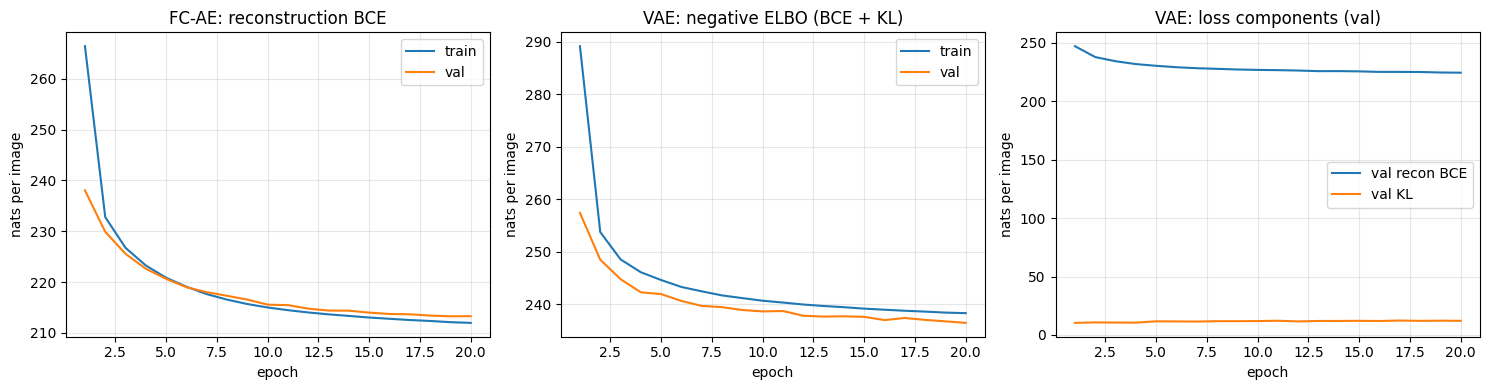

In [8]:
ep = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(ep, [h["loss"] for h in hist_ae["train"]], label="train")
axes[0].plot(ep, [h["loss"] for h in hist_ae["val"]],   label="val")
axes[0].set_title("FC-AE: reconstruction BCE")

axes[1].plot(ep, [h["loss"] for h in hist_vae["train"]], label="train")
axes[1].plot(ep, [h["loss"] for h in hist_vae["val"]],   label="val")
axes[1].set_title("VAE: negative ELBO (BCE + KL)")

axes[2].plot(ep, [h["recon"] for h in hist_vae["val"]], label="val recon BCE")
axes[2].plot(ep, [h["kl"]    for h in hist_vae["val"]], label="val KL")
axes[2].set_title("VAE: loss components (val)")

for ax in axes:
    ax.set_xlabel("epoch"); ax.set_ylabel("nats per image"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### Quantitative test-set metrics
MSE and PSNR are computed per image on [0, 1] pixels. The VAE is evaluated with $z=\mu$ (deterministic), which is the fair way to measure its reconstruction quality.

In [9]:
@torch.no_grad()
def evaluate(model, loader, is_vae):
    model.eval()
    mse_all, bce_all, kl_all, labels, latents = [], [], [], [], []
    for x, y in loader:
        x = x.to(device)
        if is_vae:
            x_hat, mu, logvar = model(x)
            z = mu
            kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1)
            kl_all.append(kl.cpu())
        else:
            x_hat, z = model(x)
        mse_all.append(((x_hat - x) ** 2).flatten(1).mean(1).cpu())
        bce_all.append(F.binary_cross_entropy(x_hat, x, reduction="none").flatten(1).sum(1).cpu())
        labels.append(y); latents.append(z.cpu())
    out = {
        "mse": torch.cat(mse_all), "bce": torch.cat(bce_all),
        "y": torch.cat(labels), "z": torch.cat(latents),
    }
    out["psnr"] = 10 * torch.log10(1.0 / out["mse"].clamp_min(1e-10))
    if is_vae: out["kl"] = torch.cat(kl_all)
    return out

res_ae  = evaluate(fc_ae, test_loader, is_vae=False)
res_vae = evaluate(vae,   test_loader, is_vae=True)

print(f"{'Metric':<28}{'FC-AE':>12}{'VAE':>12}")
print("-" * 52)
print(f"{'Test MSE (per pixel)':<28}{res_ae['mse'].mean():>12.5f}{res_vae['mse'].mean():>12.5f}")
print(f"{'Test PSNR (dB)':<28}{res_ae['psnr'].mean():>12.2f}{res_vae['psnr'].mean():>12.2f}")
print(f"{'Test recon BCE (nats/img)':<28}{res_ae['bce'].mean():>12.2f}{res_vae['bce'].mean():>12.2f}")
print(f"{'Test KL (nats/img)':<28}{'—':>12}{res_vae['kl'].mean():>12.2f}")
print(f"{'Test negative ELBO':<28}{'—':>12}{(res_vae['bce'] + res_vae['kl']).mean():>12.2f}")

Metric                             FC-AE         VAE
----------------------------------------------------
Test MSE (per pixel)             0.01018     0.01513
Test PSNR (dB)                     21.02       19.08
Test recon BCE (nats/img)         214.43      225.46
Test KL (nats/img)                     —       12.02
Test negative ELBO                     —      237.48


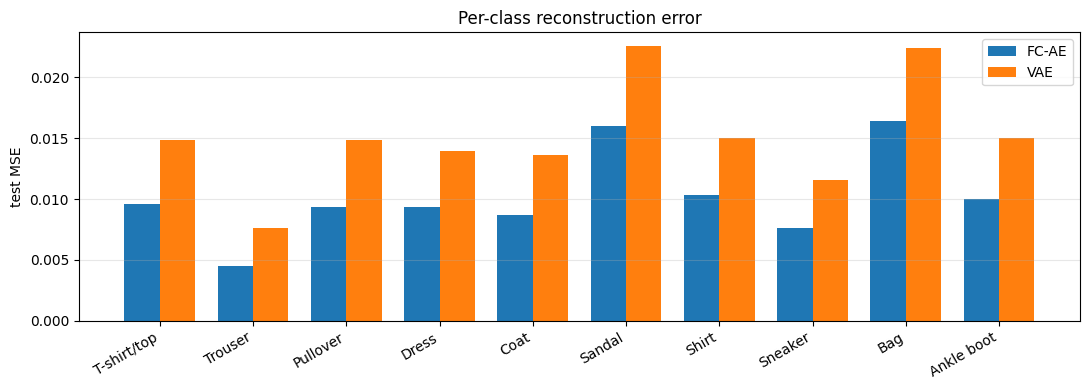

T-shirt/top  FC-AE 0.00957   VAE 0.01482
Trouser      FC-AE 0.00453   VAE 0.00762
Pullover     FC-AE 0.00938   VAE 0.01482
Dress        FC-AE 0.00936   VAE 0.01391
Coat         FC-AE 0.00872   VAE 0.01360
Sandal       FC-AE 0.01598   VAE 0.02256
Shirt        FC-AE 0.01032   VAE 0.01504
Sneaker      FC-AE 0.00759   VAE 0.01154
Bag          FC-AE 0.01640   VAE 0.02240
Ankle boot   FC-AE 0.00998   VAE 0.01503


In [10]:
# Per-class reconstruction MSE
cls_ae  = [res_ae["mse"][res_ae["y"] == c].mean().item()  for c in range(10)]
cls_vae = [res_vae["mse"][res_vae["y"] == c].mean().item() for c in range(10)]

idx = np.arange(10); w = 0.38
plt.figure(figsize=(11, 4))
plt.bar(idx - w/2, cls_ae,  w, label="FC-AE")
plt.bar(idx + w/2, cls_vae, w, label="VAE")
plt.xticks(idx, CLASSES, rotation=30, ha="right")
plt.ylabel("test MSE"); plt.title("Per-class reconstruction error"); plt.legend(); plt.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

for c in range(10):
    print(f"{CLASSES[c]:<12} FC-AE {cls_ae[c]:.5f}   VAE {cls_vae[c]:.5f}")

### Visual reconstructions

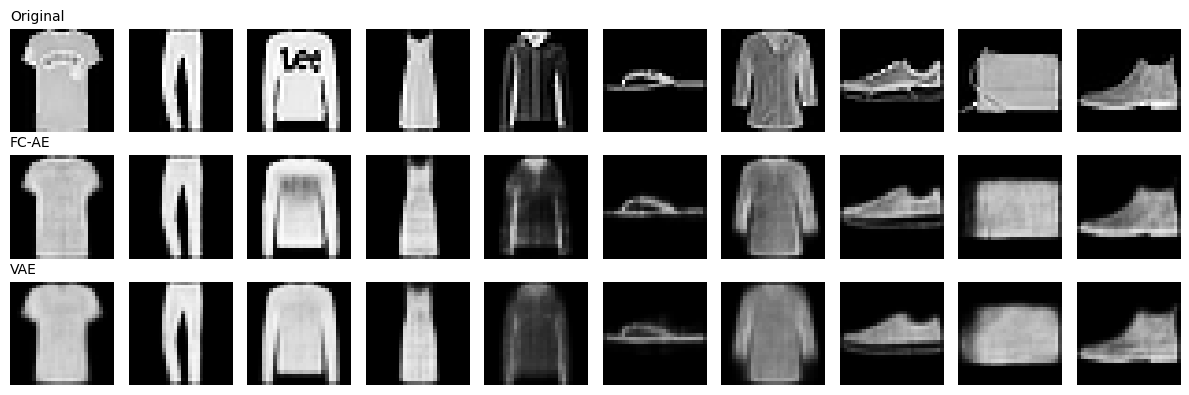

In [11]:
@torch.no_grad()
def show_reconstructions(n=10):
    fc_ae.eval(); vae.eval()
    # one example per class
    xs = torch.stack([test_set[(test_set.targets == c).nonzero()[0].item()][0] for c in range(n)]).to(device)
    r_ae, _ = fc_ae(xs)
    r_vae, _, _ = vae(xs)
    rows = [("Original", xs), ("FC-AE", r_ae), ("VAE", r_vae)]
    fig, axes = plt.subplots(3, n, figsize=(n * 1.2, 4))
    for r, (title, imgs) in enumerate(rows):
        for c in range(n):
            axes[r, c].imshow(imgs[c, 0].cpu(), cmap="gray", vmin=0, vmax=1)
            axes[r, c].axis("off")
        axes[r, 0].set_title(title, loc="left", fontsize=10)
    plt.tight_layout(); plt.show()

show_reconstructions()

### Latent space structure
t-SNE projects the 16-D test codes to 2-D. A linear probe (logistic regression on the codes, trained on test samples 0–7999 and scored on 8000–9999) measures how linearly separable the classes are in each latent space.

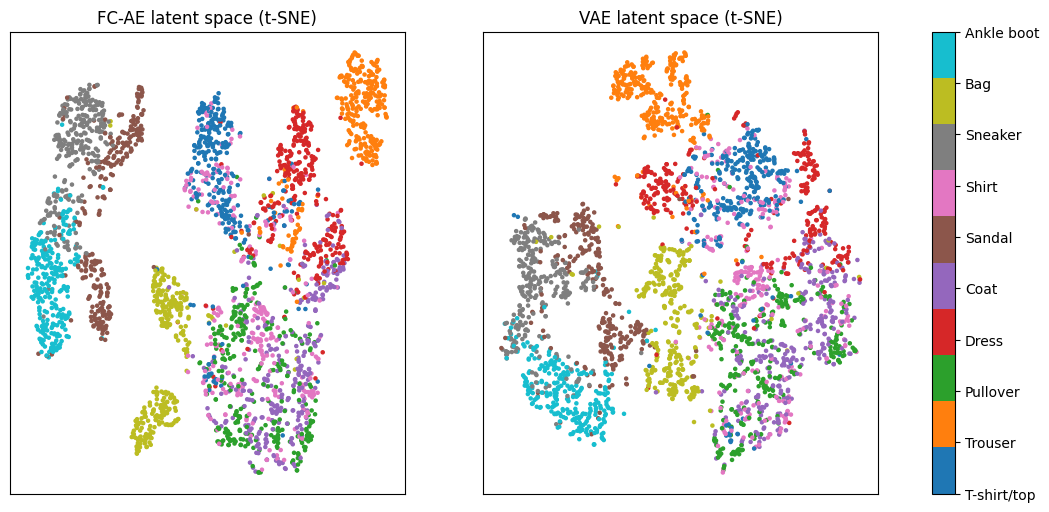

Linear-probe accuracy  FC-AE: 0.815   VAE: 0.740
FC-AE: latent mean |avg| = 0.792, latent std avg = 2.307
VAE: latent mean |avg| = 0.027, latent std avg = 0.389


In [12]:
N_TSNE = 3000
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, res) in zip(axes, [("FC-AE", res_ae), ("VAE", res_vae)]):
    emb = TSNE(n_components=2, init="pca", perplexity=30, random_state=SEED).fit_transform(res["z"][:N_TSNE].numpy())
    sc = ax.scatter(emb[:, 0], emb[:, 1], c=res["y"][:N_TSNE].numpy(), cmap="tab10", s=5)
    ax.set_title(f"{name} latent space (t-SNE)"); ax.set_xticks([]); ax.set_yticks([])
cbar = fig.colorbar(sc, ax=axes, ticks=range(10)); cbar.ax.set_yticklabels(CLASSES)
plt.show()

def linear_probe(res):
    Z, Y = res["z"].numpy(), res["y"].numpy()
    clf = LogisticRegression(max_iter=2000).fit(Z[:8000], Y[:8000])
    return clf.score(Z[8000:], Y[8000:])

print(f"Linear-probe accuracy  FC-AE: {linear_probe(res_ae):.3f}   VAE: {linear_probe(res_vae):.3f}")

# Is the latent distribution close to the N(0, I) prior?
for name, res in [("FC-AE", res_ae), ("VAE", res_vae)]:
    z = res["z"]
    print(f"{name}: latent mean |avg| = {z.mean(0).abs().mean():.3f}, latent std avg = {z.std(0).mean():.3f}")

### Generation from the prior
Decode $z \sim \mathcal{N}(0, I)$. The VAE is trained so that this prior matches the latent distribution it uses, so its samples should look like clothing. The FC-AE latent space has no such constraint, so random codes mostly fall in regions the decoder never saw. To be fair, the FC-AE is also sampled from a Gaussian fitted to its own test codes.

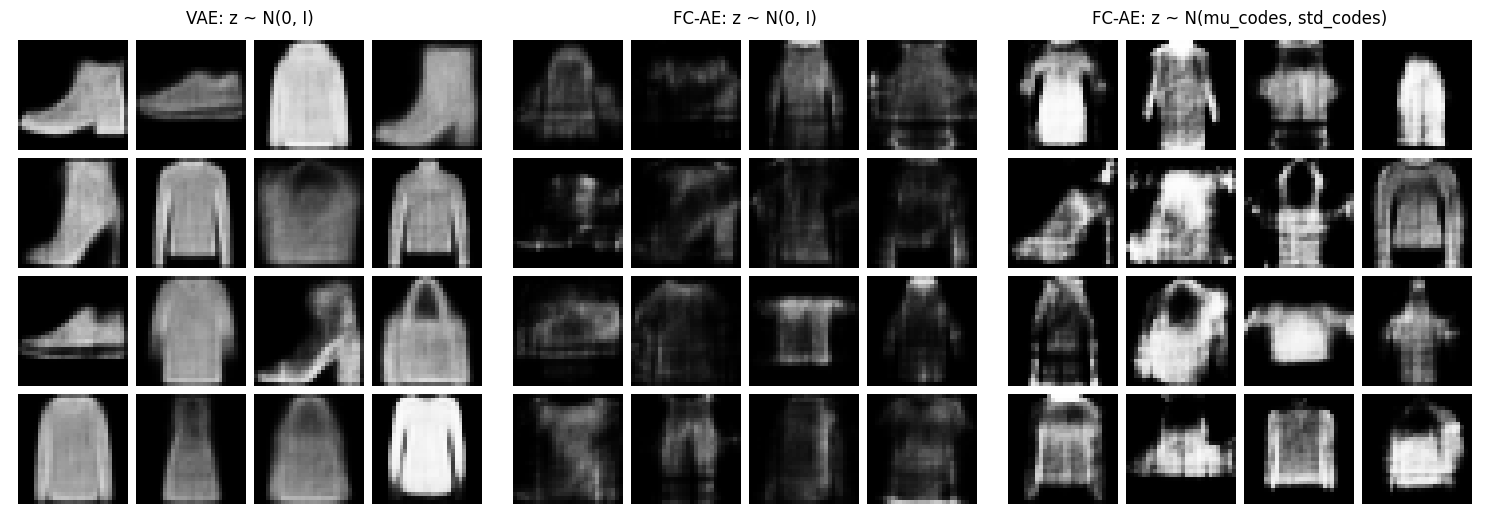

In [13]:
@torch.no_grad()
def show_samples(n=16):
    fc_ae.eval(); vae.eval()
    z = torch.randn(n, LATENT_DIM, device=device)
    # Gaussian fitted to the FC-AE's actual codes
    mu_ae, std_ae = res_ae["z"].mean(0).to(device), res_ae["z"].std(0).to(device)
    samples = {
        "VAE: z ~ N(0, I)":                  vae.decode(z),
        "FC-AE: z ~ N(0, I)":                fc_ae.decode(z),
        "FC-AE: z ~ N(mu_codes, std_codes)": fc_ae.decode(mu_ae + std_ae * torch.randn_like(z)),
    }
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
    for ax, (title, imgs) in zip(axes, samples.items()):
        grid = make_grid(imgs.cpu(), nrow=4, padding=2, pad_value=1)
        ax.imshow(grid.permute(1, 2, 0)); ax.set_title(title); ax.axis("off")
    plt.tight_layout(); plt.show()

show_samples()

### Latent interpolation
Linearly interpolate between the codes of two test images (an ankle boot and a T-shirt). Smooth, plausible intermediate images indicate a continuous latent space.

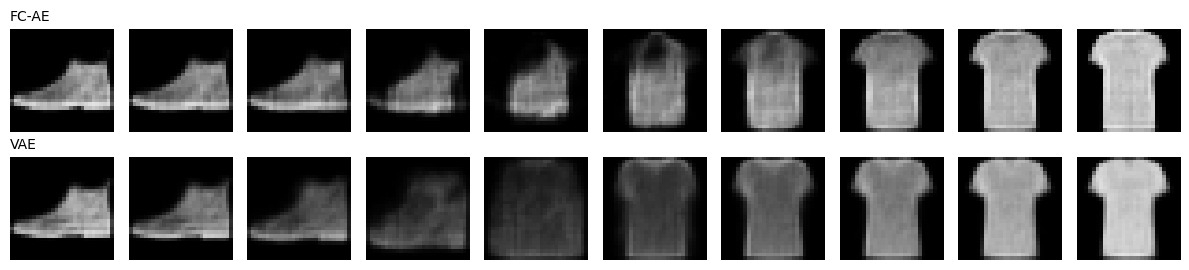

In [14]:
@torch.no_grad()
def interpolate(model, is_vae, a_idx, b_idx, steps=10):
    model.eval()
    xa = test_set[a_idx][0].unsqueeze(0).to(device)
    xb = test_set[b_idx][0].unsqueeze(0).to(device)
    za = model.encode(xa)[0] if is_vae else model.encode(xa)
    zb = model.encode(xb)[0] if is_vae else model.encode(xb)
    if za.dim() == 1: za, zb = za.unsqueeze(0), zb.unsqueeze(0)
    alphas = torch.linspace(0, 1, steps, device=device).unsqueeze(1)
    return model.decode((1 - alphas) * za + alphas * zb).cpu()

a = (test_set.targets == 9).nonzero()[0].item()   # ankle boot
b = (test_set.targets == 0).nonzero()[0].item()   # T-shirt
fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
for r, (name, m, v) in enumerate([("FC-AE", fc_ae, False), ("VAE", vae, True)]):
    imgs = interpolate(m, v, a, b)
    for c in range(10):
        axes[r, c].imshow(imgs[c, 0], cmap="gray", vmin=0, vmax=1); axes[r, c].axis("off")
    axes[r, 0].set_title(name, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 2.6 Discussion

**Training.** Both models trained smoothly. Train and validation loss stay close the whole time, so neither model overfits. The FC-AE was still improving very slightly at epoch 20, but only by about 0.1–0.2 nats per epoch, so more training would not change the comparison. For the VAE, the training loss is a bit higher than the validation loss. This is expected: during training the latent code is sampled with noise, while at evaluation we use the mean $\mu$ directly. The KL term settled at around 12 nats instead of dropping to zero, so the VAE is actually using its latent space.

**Reconstruction.** The FC-AE reconstructs better on every metric: test MSE of 0.0102 vs 0.0151, PSNR of 21.0 dB vs 19.1 dB, and reconstruction BCE of 214.4 vs 225.5 nats per image. It also wins on every one of the 10 classes. This makes sense. The FC-AE's only job is reconstruction, so it can place codes wherever is most useful. The VAE also has to keep its codes close to a standard Gaussian, and it learns with noise added to the codes, so its reconstructions come out blurrier. The gap in reconstruction loss (about 11 nats) is roughly the size of the KL term (12 nats). That is the price the VAE pays for a regularised latent space. Looking at the classes, Trousers are easiest for both models (MSE 0.0045 for the FC-AE, 0.0076 for the VAE), since they are a simple, consistent shape. Bags and Sandals are hardest (around 0.016 for the FC-AE and 0.022 for the VAE), because bags vary a lot in shape and handles, and sandals have thin straps that are hard to reproduce. In the reconstruction images, both models keep the overall shape but lose fine details such as the "Lee" logo on the pullover, and the VAE's outputs are visibly smoother.

**Latent space.** The VAE's codes are centred almost exactly at zero (average absolute mean 0.03), while the FC-AE's codes are off-centre (0.79) and spread out much more widely (average std 2.31). This shows the KL term at work. The VAE's code means have an average std of only 0.39 rather than 1. The KL term only charges for dimensions the model actually uses, so the VAE likely relies on a few informative dimensions and leaves the rest close to the prior. In the t-SNE plots, both models group images by clothing type without ever seeing labels. Trousers, Bags, and footwear form clear clusters, while Shirt, Pullover, and Coat overlap in both. The FC-AE's clusters are tighter, and its linear-probe accuracy is higher (81.5% vs 74.0%), because it keeps more detail about each image in its code.

**Generation.** This is where the VAE clearly wins. Decoding random $z \sim \mathcal{N}(0, I)$ through the VAE gives recognisable boots, sneakers, tops, and bags, though they are blurry. The same random codes give dark, noisy, meaningless images from the FC-AE, because they mostly land outside the region its codes actually occupy. Sampling from a Gaussian fitted to the FC-AE's own codes gives brighter, more clothing-like shapes, but many are distorted or mix features from different items, because the real code distribution is not Gaussian and has gaps. In the interpolation from ankle boot to T-shirt, the VAE fades smoothly from one item to the other, with dim, blurry frames in the middle. The FC-AE's in-between frames look more like a messy overlay of the two.

**Takeaway.** The plain autoencoder is the better compressor: lower error, sharper reconstructions, and more informative codes. The VAE gives up some reconstruction quality in exchange for a smooth, well-organised latent space you can sample from, which is what makes it a generative model.